In [36]:
# Since typing pandas or numpy every single time is too long and tedious, we assign them shorter nicknames like pd and np.
# You can technically use any name, such as a wolverine instead of pd and np, but pd and np are the standard conventions used by data scientists.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
# Suppress Pandas SettingWithCopyWarning
pd.options.mode.chained_assignment = None

In [37]:
from sklearn import set_config

set_config(display="text")
model = LinearRegression()

In [38]:
df2018 = pd.read_csv('germany2018.csv')
df2019 = pd.read_csv('germany2019.csv')
df2020 = pd.read_csv('germany2020.csv')
df2021 = pd.read_csv('germany2021.csv')
df2022 = pd.read_csv('germany2022.csv')
df2023 = pd.read_csv('germany2023.csv')
df2024 = pd.read_csv('germany2024.csv')
df2025 = pd.read_csv('germany2025.csv')

dfWC2018 = pd.read_csv('germany2018WC.csv')
dfWC2022 = pd.read_csv('germany2022WC.csv')
dfWC2026 = pd.read_csv('germany2026WC.csv')

years = range(2018, 2026)
yearly_dfs = {
    year: pd.read_csv(f'germany{year}.csv')
    for year in years
}
yearly_dfs[2023] = yearly_dfs[2023].rename(
    columns={'Round': 'Comp'}
)

for year, yearly_df in yearly_dfs.items():
    if yearly_df.columns.duplicated().any():
        print(f"Duplicate columns in {year}:",
              yearly_df.columns[
                  yearly_df.columns.duplicated()
              ].tolist())
yearly_dfs

{2018:           Date           Time            Comp           Round  Day    Venue  \
 0   2016-09-04  20:45 (14:45)             WCQ     First round  Sun     Away   
 1   2016-10-08  20:45 (14:45)             WCQ     First round  Sat     Home   
 2   2016-10-11  20:45 (14:45)             WCQ     First round  Tue     Home   
 3   2016-11-11  20:45 (14:45)             WCQ     First round  Fri     Away   
 4   2017-03-26  20:00 (12:00)             WCQ     First round  Sun     Away   
 5   2017-06-10  20:45 (14:45)             WCQ     First round  Sat     Home   
 6   2017-09-01  20:45 (14:45)             WCQ     First round  Fri     Away   
 7   2017-09-04  20:45 (14:45)             WCQ     First round  Mon     Home   
 8   2017-10-05  19:45 (14:45)             WCQ     First round  Thu     Away   
 9   2017-10-08  20:45 (14:45)             WCQ     First round  Sun     Home   
 10  2018-03-23  20:45 (15:45)  Friendlies (M)  Friendlies (M)  Fri     Home   
 11  2018-03-27  20:45 (14:45)  Fr

In [39]:
columns_to_remove = [
    'Day', 
    'Attendance',
    'Formation',
    'Opp Formation',
    'Match Report',
    'Notes',
    'Referee'
]

for year, yearly_df in yearly_dfs.items():
    yearly_df.drop(columns=columns_to_remove, errors='ignore', inplace=True)
yearly_dfs

{2018:           Date           Time            Comp           Round    Venue Result  \
 0   2016-09-04  20:45 (14:45)             WCQ     First round     Away      W   
 1   2016-10-08  20:45 (14:45)             WCQ     First round     Home      W   
 2   2016-10-11  20:45 (14:45)             WCQ     First round     Home      W   
 3   2016-11-11  20:45 (14:45)             WCQ     First round     Away      W   
 4   2017-03-26  20:00 (12:00)             WCQ     First round     Away      W   
 5   2017-06-10  20:45 (14:45)             WCQ     First round     Home      W   
 6   2017-09-01  20:45 (14:45)             WCQ     First round     Away      W   
 7   2017-09-04  20:45 (14:45)             WCQ     First round     Home      W   
 8   2017-10-05  19:45 (14:45)             WCQ     First round     Away      W   
 9   2017-10-08  20:45 (14:45)             WCQ     First round     Home      W   
 10  2018-03-23  20:45 (15:45)  Friendlies (M)  Friendlies (M)     Home      D   
 11  2018-

In [40]:
matches_df = pd.concat(
    yearly_dfs.values(),
    ignore_index=True
)
matches_df = matches_df[matches_df['Comp'] != 'World Cup'].reset_index(drop=True)
matches_df


,Date,Time,Comp,Round,Venue,Result,GF,GA,Opponent,Poss,Captain
0,2016-09-04,20:45 (14:45),WCQ,First round,Away,W,3,0,no Norway,NaN,Manuel Neuer
1,2016-10-08,20:45 (14:45),WCQ,First round,Home,W,3,0,cz Czechia,NaN,Manuel Neuer
2,2016-10-11,20:45 (14:45),WCQ,First round,Home,W,2,0,nir Northern Ireland,NaN,Manuel Neuer
3,2016-11-11,20:45 (14:45),WCQ,First round,Away,W,8,0,sm San Marino,NaN,Sami Khedira
4,2017-03-26,20:00 (12:00),WCQ,First round,Away,W,4,1,az Azerbaijan,NaN,Sami Khedira
...,...,...,...,...,...,...,...,...,...,...,...
66,2024-07-05,18:00 (12:00),UEFA Euro,Quarter-finals,Neutral,L,1,2,es Spain,52.0,İlkay Gündoğan
67,2025-03-20,20:45 (15:45),UEFA Nations League,Quarter-finals,Away,W,2,1,it Italy,59.0,Joshua Kimmich
68,2025-03-23,20:45 (15:45),UEFA Nations League,Quarter-finals,Home,D,3,3,it Italy,57.0,Joshua Kimmich
69,2025-06-04,21:10 (15:10),UEFA Nations League,Semi-finals,Neutral,L,1,2,pt Portugal,55.0,Joshua Kimmich


In [41]:
def calculate_cycle_stats(matches):
    stats = {
        'Num_Matches': len(matches),
        'Avg_GF': matches['GF'].mean(),
        'Avg_GA': matches['GA'].mean(),
        'Avg_Goal_Difference': (matches['GF'] - matches['GA']).mean(),
        'Win_Rate': (matches['Result'] == 'W').mean(),
        'Draw_Rate': (matches['Result'] == 'D').mean(),
        'Loss_Rate': (matches['Result'] == 'L').mean(),
        'Avg_Poss': matches['Poss'].mean()
    }

    return pd.Series(stats)

In [42]:
cycles = {
    2018: ('2014-07-14', '2018-06-14'),
    2022: ('2018-07-16', '2022-11-20'),
    2026: ('2022-12-19', '2026-06-11')
}
cycle_rows = []

for wc_year, (start, end) in cycles.items():

    cycle_matches = matches_df[(matches_df['Date'] >= start) & (matches_df['Date'] < end)]

    stats = calculate_cycle_stats(cycle_matches)

    stats['WC_Year'] = wc_year

    cycle_rows.append(stats)

cycles_df = pd.DataFrame(cycle_rows)

cycles_df

,Num_Matches,Avg_GF,Avg_GA,Avg_Goal_Difference,Win_Rate,Draw_Rate,Loss_Rate,Avg_Poss,WC_Year
0,14.0,3.357143,0.642857,2.714286,0.785714,0.071429,0.142857,NaN,2018.0
1,33.0,2.909091,0.848485,2.060606,0.696970,0.181818,0.121212,70.318182,2022.0
2,24.0,1.666667,1.500000,0.166667,0.416667,0.208333,0.375000,60.222222,2026.0


In [59]:
X = cycles_df[['Avg_GF', 'Avg_GA', 'Avg_Goal_Difference']].dropna()
y = dfWC2026['GF']

In [60]:
X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=42)

In [61]:
model.fit(X_train, y_train)

LinearRegression()

In [62]:
y_pred = model.predict(X_test)
y_pred
print(model.coef_, model.intercept_)

[ 0.22365485 -0.11728242  0.34093727] 0.746342672948178


Text(0.5, 1.0, 'Model Behavior On Training Set')

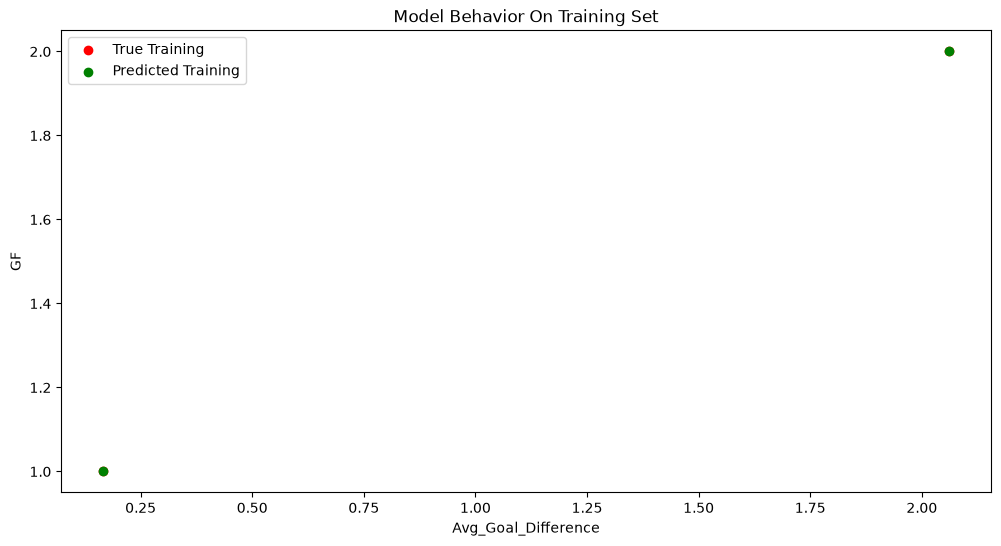

In [63]:

col_name = 'Avg_Goal_Difference'


f = plt.figure(figsize=(12,6))
plt.scatter(X_train[col_name], y_train, color = "red")
plt.scatter(X_train[col_name], model.predict(X_train), color = "green")

plt.legend(['True Training','Predicted Training'])
plt.xlabel(col_name)
plt.ylabel(dfWC2026['GF'].name)
plt.title("Model Behavior On Training Set")

In [ ]:
df2018.columns, df2019.columns, df2020.columns, df2021.columns, df2022.columns, df2023.columns, df2024.columns, df2025.columns

(Index(['Date', 'Time', 'Comp', 'Round', 'Day', 'Venue', 'Result', 'GF', 'GA',
        'Opponent', 'Poss', 'Attendance', 'Captain', 'Formation',
        'Opp Formation', 'Referee', 'Match Report', 'Notes'],
       dtype='str'),
 Index(['Date', 'Time', 'Comp', 'Round', 'Day', 'Venue', 'Result', 'GF', 'GA',
        'Opponent', 'Poss', 'Attendance', 'Captain', 'Formation',
        'Opp Formation', 'Referee', 'Match Report', 'Notes'],
       dtype='str'),
 Index(['Date', 'Time', 'Comp', 'Round', 'Day', 'Venue', 'Result', 'GF', 'GA',
        'Opponent', 'Poss', 'Attendance', 'Captain', 'Formation',
        'Opp Formation', 'Referee', 'Match Report', 'Notes'],
       dtype='str'),
 Index(['Date', 'Time', 'Comp', 'Round', 'Day', 'Venue', 'Result', 'GF', 'GA',
        'Opponent', 'Poss', 'Attendance', 'Captain', 'Formation',
        'Opp Formation', 'Referee', 'Match Report', 'Notes'],
       dtype='str'),
 Index(['Date', 'Time', 'Comp', 'Round', 'Day', 'Venue', 'Result', 'GF', 'GA',
        '

In [ ]:
df2021.dtypes

Date                 str
Time                 str
Comp                 str
Round                str
Day                  str
Venue                str
Result               str
GF                 int64
GA                 int64
Opponent             str
Poss             float64
Attendance       float64
Captain              str
Formation            str
Opp Formation        str
Referee              str
Match Report         str
Notes            float64
dtype: object

In [ ]:
columns_to_remove = [
    'Day', 
    'Attendance',
    'Formation',
    'Opp Formation',
    'Match Report',
    'Notes',
    'Referee'
]
df2018.drop(columns_to_remove, axis=1, inplace=True)
df2019.drop(columns_to_remove, axis=1, inplace=True)
df2020.drop(columns_to_remove, axis=1, inplace=True)
df2021.drop(columns_to_remove, axis=1, inplace=True)
df2022.drop(columns_to_remove, axis=1, inplace=True)
df2023.drop(columns_to_remove, axis=1, inplace=True)
df2024.drop(columns_to_remove, axis=1, inplace=True)
df2025.drop(columns_to_remove, axis=1, inplace=True)

In [ ]:
df2020.columns

Index(['Date', 'Time', 'Comp', 'Round', 'Venue', 'Result', 'GF', 'GA',
       'Opponent', 'Poss', 'Captain'],
      dtype='str')

In [ ]:
df = pd.concat([df2018, df2019, df2020, df2021, df2022, df2023, df2024, df2025], ignore_index=True)
df

,Date,Time,Comp,Round,Venue,Result,GF,GA,Opponent,Poss,Captain
0,2016-09-04,20:45 (14:45),WCQ,First round,Away,W,3,0,no Norway,NaN,Manuel Neuer
1,2016-10-08,20:45 (14:45),WCQ,First round,Home,W,3,0,cz Czechia,NaN,Manuel Neuer
2,2016-10-11,20:45 (14:45),WCQ,First round,Home,W,2,0,nir Northern Ireland,NaN,Manuel Neuer
3,2016-11-11,20:45 (14:45),WCQ,First round,Away,W,8,0,sm San Marino,NaN,Sami Khedira
4,2017-03-26,20:00 (12:00),WCQ,First round,Away,W,4,1,az Azerbaijan,NaN,Sami Khedira
...,...,...,...,...,...,...,...,...,...,...,...
72,2024-07-05,18:00 (12:00),UEFA Euro,Quarter-finals,Neutral,L,1,2,es Spain,52.0,İlkay Gündoğan
73,2025-03-20,20:45 (15:45),UEFA Nations League,Quarter-finals,Away,W,2,1,it Italy,59.0,Joshua Kimmich
74,2025-03-23,20:45 (15:45),UEFA Nations League,Quarter-finals,Home,D,3,3,it Italy,57.0,Joshua Kimmich
75,2025-06-04,21:10 (15:10),UEFA Nations League,Semi-finals,Neutral,L,1,2,pt Portugal,55.0,Joshua Kimmich


In [ ]:
df['Date'] = pd.to_datetime(df['Date'], yearfirst=True, errors='coerce')


In [ ]:
df.isna().sum()
df.loc[[df['Time'].isna().idxmax()]]
df.drop(53, inplace=True)


(array([10.,  0., 15.,  0., 23.,  0., 11.,  0.,  7.,  0.,  0.,  2.,  0.,
         3.,  0.,  2.,  0.,  2.,  0.,  1.]),
 array([0.  , 0.45, 0.9 , 1.35, 1.8 , 2.25, 2.7 , 3.15, 3.6 , 4.05, 4.5 ,
        4.95, 5.4 , 5.85, 6.3 , 6.75, 7.2 , 7.65, 8.1 , 8.55, 9.  ]),
 <BarContainer object of 20 artists>)

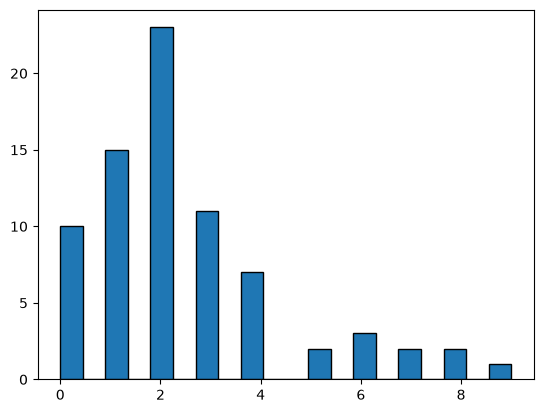

In [ ]:
plt.hist(df['GF'], bins = 20, edgecolor = 'black')

(array([ 1.,  6.,  0., 11.,  0., 13., 13.,  0., 12.,  0.,  7.,  5.,  0.,
         1.,  0.,  3.,  1.,  0.,  2.,  1.]),
 array([-3. , -2.4, -1.8, -1.2, -0.6,  0. ,  0.6,  1.2,  1.8,  2.4,  3. ,
         3.6,  4.2,  4.8,  5.4,  6. ,  6.6,  7.2,  7.8,  8.4,  9. ]),
 <BarContainer object of 20 artists>)

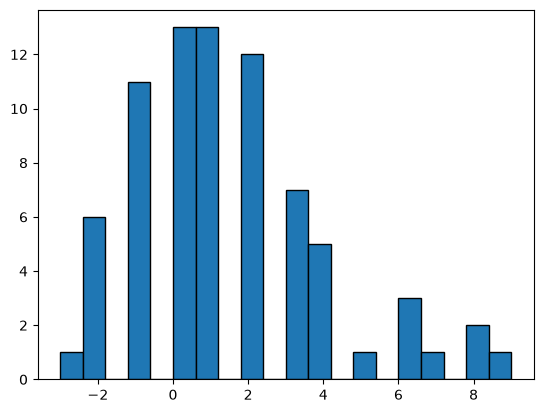

In [ ]:
plt.hist(df['GF'] - df['GA'], bins = 20, edgecolor = 'black')

In [ ]:
corrs = df.corr(numeric_only=True)
corrs

,GF,GA,Poss
GF,1.000000,-0.303744,0.431318
GA,-0.303744,1.000000,-0.538332
Poss,0.431318,-0.538332,1.000000


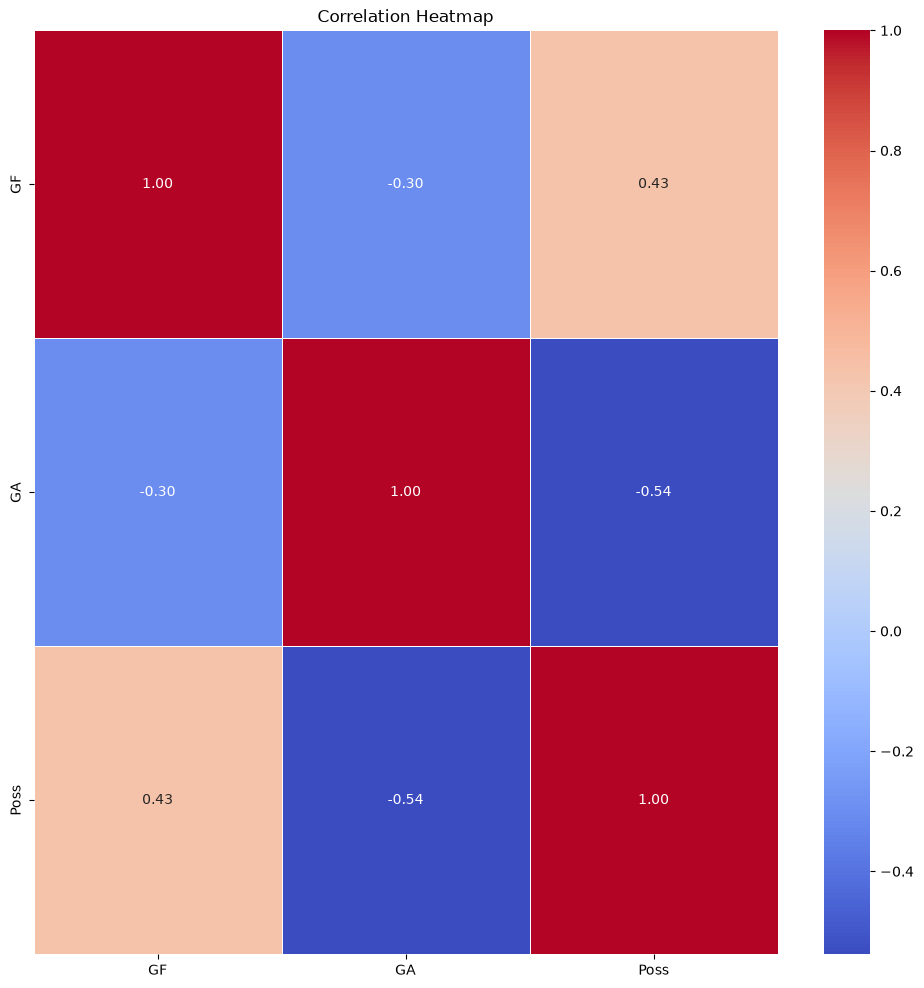

In [ ]:
plt.figure(figsize=(12, 12)) # Adjust figure size as needed
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap')
plt.show()